# Ibovespa ML Analysis — Análise de Dados & Machine Learning Aplicado ao Mercado Financeiro

Este projeto analisa dados históricos do índice IBOVESPA para explorar padrões, testar a estacionariedade da série sob diferentes transformações, e avaliar criticamente o uso de modelos de séries temporais (Naive, SeasonalNaive, SeasonalWindowAverage, AutoARIMA e Prophet) para prever a direção do fechamento do dia seguinte.

O foco é analítico e educacional: o objetivo não é construir um modelo operacional de trading, e sim entender os limites e as armadilhas de aplicar Machine Learning a uma série financeira notoriamente ruidosa e não estacionária.

> ⚠️ Este projeto não constitui recomendação de investimento.


## Importando Bibliotecas

In [ ]:
!pip install statsforecast

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import yfinance as yf

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

In [5]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, SeasonalWindowAverage, AutoARIMA
from statsforecast.utils import ConformalIntervals

In [6]:
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics

In [ ]:
df = yf.download('^BVSP', start='2008-01-01', end='2025-07-01', interval='1d')

In [7]:
df = df[['Close', "High", "Low", "Open", "Volume"]].dropna().reset_index()
df.columns = ['Data', 'Fechamento', 'Alta', 'Baixa', 'Abertura', 'Volume']

In [8]:
df.head(2)

,Data,Fechamento,Alta,Baixa,Abertura,Volume
0,2008-01-02,62815.0,63906.0,62659.0,63885.0,2980200
1,2008-01-03,62892.0,63129.0,62556.0,62814.0,1895800


In [9]:
df.tail(2)

,Data,Fechamento,Alta,Baixa,Abertura,Volume
4329,2025-06-26,137114.0,137353.0,135756.0,135767.0,8023300
4330,2025-06-27,136866.0,137209.0,136469.0,137113.0,6244500


## Tratamento dos Dados

In [10]:
df.isnull().sum()

Data          0
Fechamento    0
Alta          0
Baixa         0
Abertura      0
Volume        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4331 entries, 0 to 4330
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Data        4331 non-null   datetime64[ns]
 1   Fechamento  4331 non-null   float64       
 2   Alta        4331 non-null   float64       
 3   Baixa       4331 non-null   float64       
 4   Abertura    4331 non-null   float64       
 5   Volume      4331 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 203.1 KB


In [13]:
df.shape

(4331, 6)

## Análise Exploratória

In [14]:
def EDA (df, y):
  ax = df.plot(x='Data', y=y, kind='line', label='Preço de ' + str(y))
  ax.set_title('Indíce IBOVESPA ' + str(y))
  ax.set_xlabel('Data')
  ax.set_ylabel('Preço')
  fig = ax.get_figure()
  fig.set_figwidth(15)
  fig.set_figheight(5)
  plt.show()

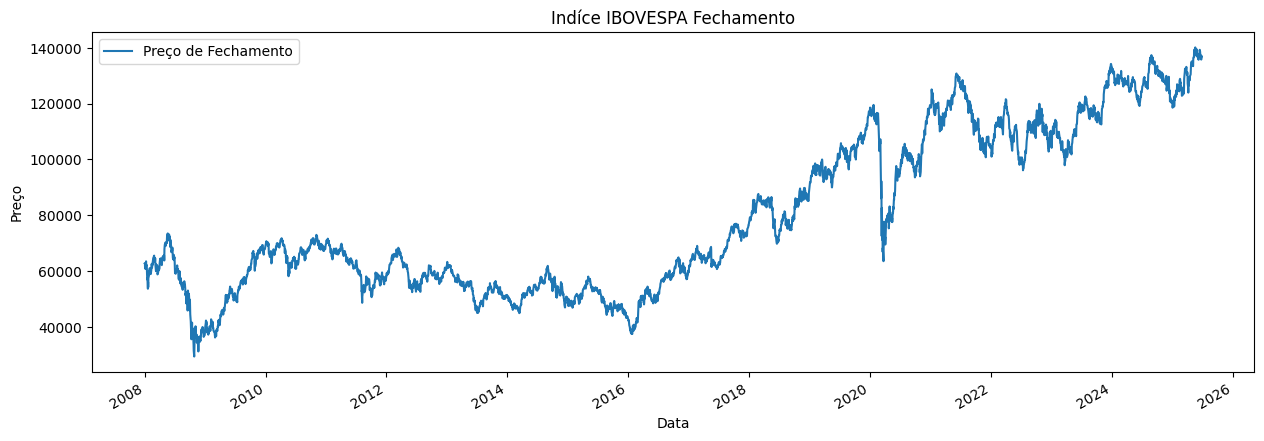

In [15]:
EDA(df,'Fechamento')

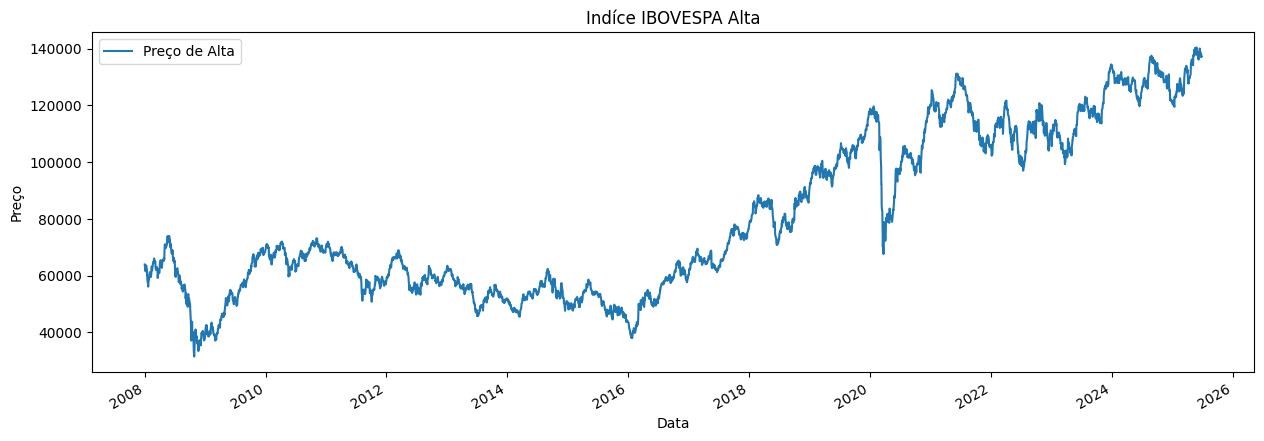

In [16]:
EDA(df,'Alta')

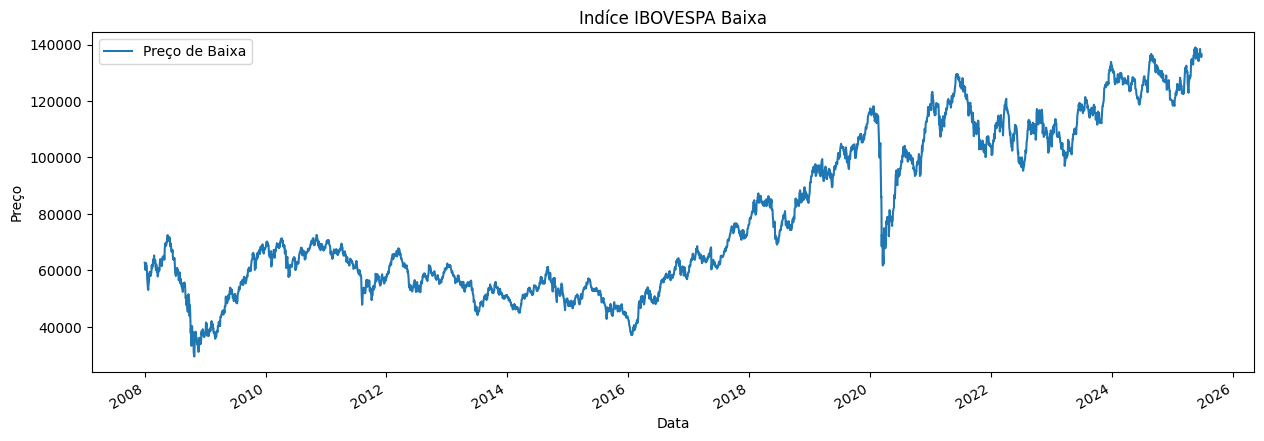

In [17]:
EDA(df,'Baixa')

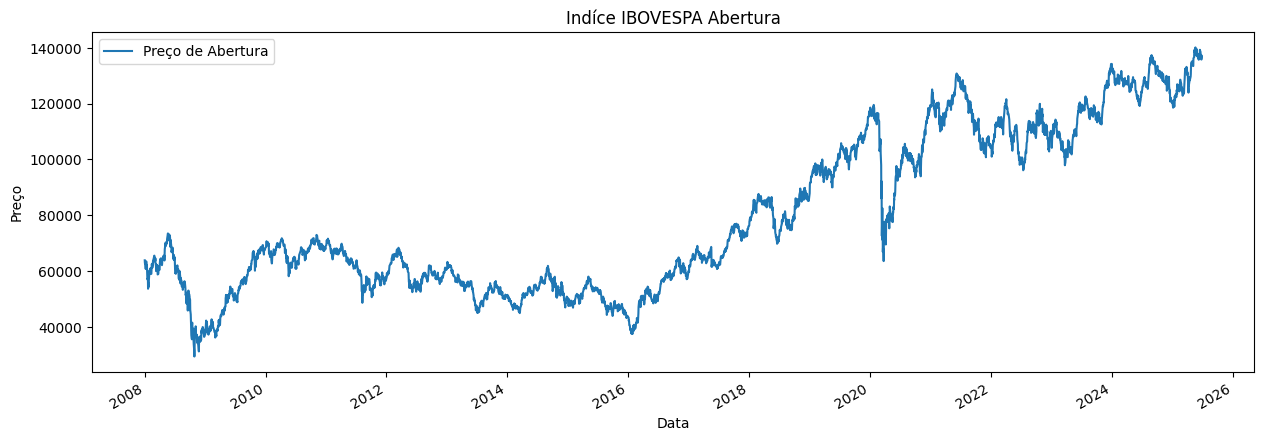

In [18]:
EDA(df,'Abertura')

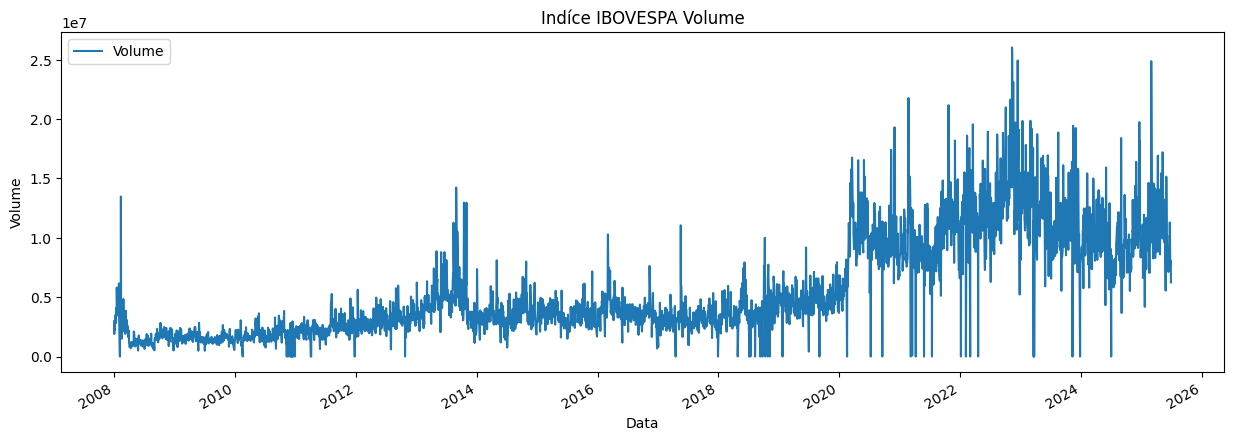

In [19]:
ax = df.plot(x='Data', y='Volume', kind='line', label='Volume')
ax.set_title('Indíce IBOVESPA Volume')
ax.set_xlabel('Data')
ax.set_ylabel('Volume')
fig = ax.get_figure()
fig.set_figwidth(15)
fig.set_figheight(5)
plt.show()

In [20]:
def EDA_Time(df, y):
  colunas_tirar = [col for col in df.columns if col != y and col != 'Data']
  df_close = df.set_index('Data')
  df_close = df_close.drop(colunas_tirar, axis=1)
  resultados = seasonal_decompose(df_close, period=1)
  fig, (ax1,ax2,ax3,ax4) = plt.subplots(4,1, figsize = (15,10))
  resultados.observed.plot(ax=ax1)
  resultados.trend.plot(ax=ax2)
  resultados.seasonal.plot(ax=ax3)
  resultados.resid.plot(ax=ax4)
  plt.tight_layout()
  plot_acf(df_close[y])
  plot_pacf(df_close[y])
  plt.show()

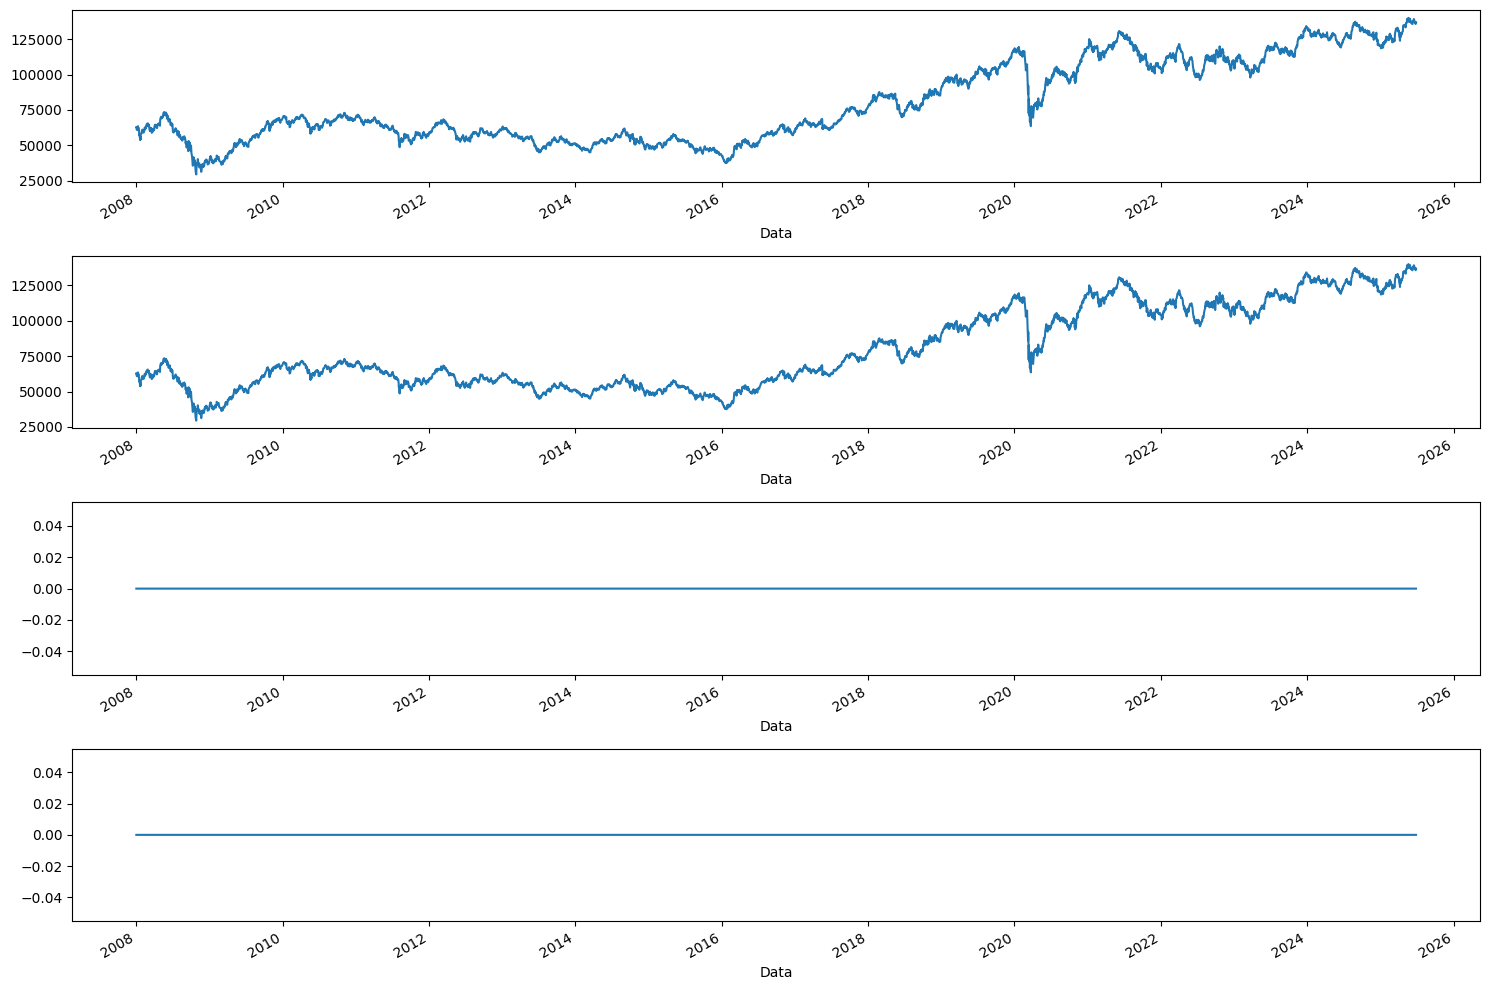

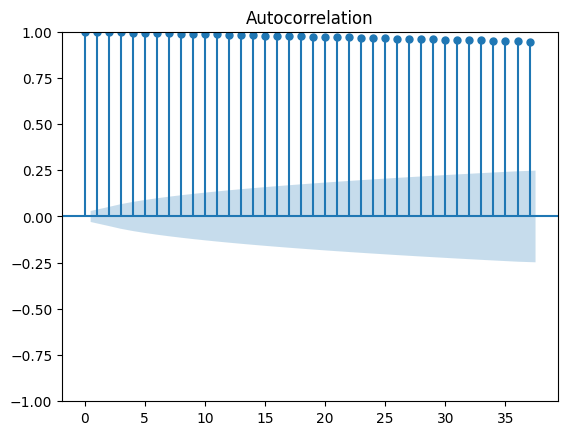

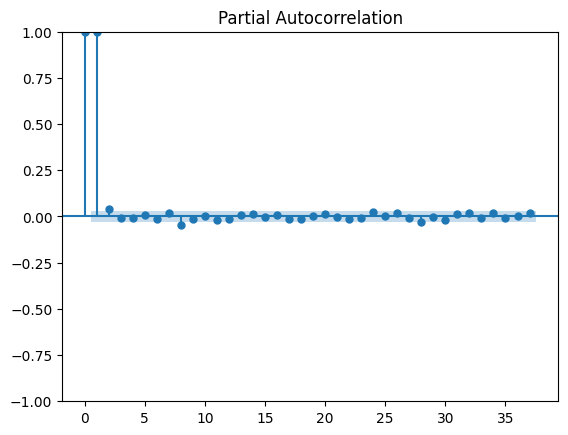

In [21]:
EDA_Time(df, 'Fechamento')

## Estacionariedade

In [22]:
def def_adf(df, y):
  colunas_tirar = [col for col in df.columns if col != y and col != 'Data']
  df_close = df.set_index('Data')
  df_close = df_close.drop(colunas_tirar, axis=1)

  X = df_close[y]
  result = adfuller(X)

  print("Teste ADF")
  print(f"Teste Estatístico: {result[0]}")
  print(f"P-Value: {result[1]}")
  print("Valores críticos:")

  if result[1] > 0.05:
    print("Não é estacionária")
  else:
    print("Estacionária")

  for key, value in result[4].items():
    print(f"\t{key}: {value}")

  df_puro = df_close
  return df_puro

In [23]:
def def_adf_ma(df, y, ma):
  colunas_tirar = [col for col in df.columns if col != y and col != 'Data']
  df_close = df.set_index('Data')
  df_close = df_close.drop(colunas_tirar, axis=1)

  # Nota: aqui subtraímos a média móvel da série (em vez de só suavizar com ela),
  # para que esta transformação remova tendência da mesma forma que def_adf_log
  # faz com a série logaritmizada — caso contrário as duas não seriam comparáveis.
  media_movel = df_close.rolling(ma).mean()
  df_s = (df_close - media_movel).dropna()

  X = df_s[y]
  result = adfuller(X)

  print("Teste ADF")
  print(f"Teste Estatístico: {result[0]}")
  print(f"P-Value: {result[1]}")
  print("Valores críticos:")

  if result[1] > 0.05:
    print("Não é estacionária")
  else:
    print("Estacionária")

  for key, value in result[4].items():
    print(f"\t{key}: {value}")

  df_ma = df_s.dropna()
  return df_ma


In [24]:
def def_adf_log(df, y, ma):
  colunas_tirar = [col for col in df.columns if col != y and col != 'Data']
  df_close = df.set_index('Data')
  df_close = df_close.drop(colunas_tirar, axis=1)

  df_log = np.log(df_close)
  ma_log = df_log.rolling(ma).mean()

  df_s = (df_log - ma_log).dropna()
  ma_s = df_s.rolling(ma).mean()
  std_s = df_s.rolling(ma).std()

  X = df_s[y]
  result = adfuller(X)

  print("Teste ADF")
  print(f"Teste Estatístico: {result[0]}")
  print(f"P-Value: {result[1]}")
  print("Valores críticos:")

  if result[1] > 0.05:
    print("Não é estacionária")
  else:
    print("Estacionária")

  for key, value in result[4].items():
    print(f"\t{key}: {value}")

  df_log = df_s.dropna()
  return df_log

In [25]:
def def_adf_diff(df, y, ma, diff):
  colunas_tirar = [col for col in df.columns if col != y and col != 'Data']
  df_close = df.set_index('Data')
  df_close = df_close.drop(colunas_tirar, axis=1)

  df_log = np.log(df_close)
  ma_log = df_log.rolling(ma).mean()

  df_s = (df_log - ma_log).dropna()

  df_diff = df_s.diff(diff).dropna()

  # Correção: o teste ADF precisa validar a série efetivamente diferenciada (df_diff),
  # não a série log-detrendizada da etapa anterior (df_s) — testar df_s aqui era
  # equivalente a repetir o teste da etapa "Logaritmo".
  X = df_diff[y]
  result = adfuller(X)

  print("Teste ADF")
  print(f"Teste Estatístico: {result[0]}")
  print(f"P-Value: {result[1]}")
  print("Valores críticos:")

  if result[1] > 0.05:
    print("Não é estacionária")
  else:
    print("Estacionária")

  for key, value in result[4].items():
    print(f"\t{key}: {value}")

  return df_diff


In [26]:
def frames(df, y, ma, diff):
  print('='*40)
  print('Dados Puros')
  df_puro = def_adf(df, y)
  print('='*40)
  print('Dados com Médias Móveis')
  df_ma = def_adf_ma(df, y, ma)
  print('='*40)
  print('Dados transformados por Logaritimo')
  df_log = def_adf_log(df, y, ma)
  print('='*40)
  print('Dados transformados com Diferenciação')
  df_diff = def_adf_diff(df, y, ma, diff)
  print('='*40)
  return df_puro, df_ma, df_log, df_diff
  print('df_puro, df_ma, df_log e df_diff armazenados')

In [27]:
df_puro, df_ma, df_log, df_diff = frames(df, 'Fechamento', 12, 1)

Dados Puros


Teste ADF
Teste Estatístico: -0.7092697700403725
P-Value: 0.8443338252432506
Valores críticos:
Não é estacionária
	1%: -3.4318639259839063
	5%: -2.862208968482777
	10%: -2.567126096698424
Dados com Médias Móveis
Teste ADF
Teste Estatístico: -14.341770663639771
P-Value: 1.0570948052841055e-26
Valores críticos:
Estacionária
	1%: -3.4318688488281657
	5%: -2.862211143217297
	10%: -2.567127254420314
Dados transformados por Logaritimo


Teste ADF
Teste Estatístico: -12.209322651238738
P-Value: 1.173638155794599e-22
Valores críticos:
Estacionária
	1%: -3.431871676283006
	5%: -2.862212392282944
	10%: -2.567127919361817
Dados transformados com Diferenciação
Teste ADF
Teste Estatístico: -18.419113851595316
P-Value: 2.1777855466138766e-30
Valores críticos:
Estacionária
	1%: -3.431875937258768
	5%: -2.862214274623216
	10%: -2.567128921428161


In [28]:
df_ma

,Fechamento
Data,
2008-01-17,-4266.083333
2008-01-18,-3354.666667
2008-01-21,-6386.416667
2008-01-22,-3586.750000
2008-01-23,-4904.000000
...,...
2025-06-23,-706.833333
2025-06-24,-170.250000
2025-06-25,-1540.333333


## Criação dos Modelos

In [29]:
def wmape(y_true, y_pred):
  return np.abs(y_true-y_pred).sum() / np.abs(y_true).sum()

In [30]:
def modelos(df, y, length, window):
  df_1 = df.copy()
  df_1.reset_index(inplace=True)
  df_1 = df_1.rename(columns={'Data':'ds', y:'y'})

  treino = df_1[:-43]
  valid = df_1[-43:]
  h = valid['ds'].nunique()
  i = treino['ds'].nunique()
  treino['unique_id'] = 'serie1'
  valid['unique_id'] = 'serie1'

  modelo = StatsForecast(models=[Naive(), SeasonalNaive(season_length=length),
                                 SeasonalWindowAverage(season_length=length, window_size=window,  prediction_intervals=ConformalIntervals(n_windows=30)),
                                 AutoARIMA(season_length=length)],
                          freq='D', n_jobs=-1)
  modelo.fit(treino)

  forecast_df = modelo.predict(h=h, level=[90])
  forecast_df = forecast_df.reset_index(drop=True).merge(valid, on=['ds', 'unique_id'], how='left')
  forecast_df = forecast_df.dropna()

  wmape1 = wmape(forecast_df['y'].values, forecast_df['Naive'].values)
  wmape2 = wmape(forecast_df['y'].values, forecast_df['SeasonalNaive'].values)
  wmape3 = wmape(forecast_df['y'].values, forecast_df['SeasWA'].values)
  wmape4 = wmape(forecast_df['y'].values, forecast_df['AutoARIMA'].values)
  all_wmape = [wmape1, wmape2, wmape3, wmape4]

  grafico = modelo.plot(treino, forecast_df, level=[90], unique_ids=['serie1'], engine ='matplotlib', max_insample_length=90)
  return grafico, forecast_df, all_wmape

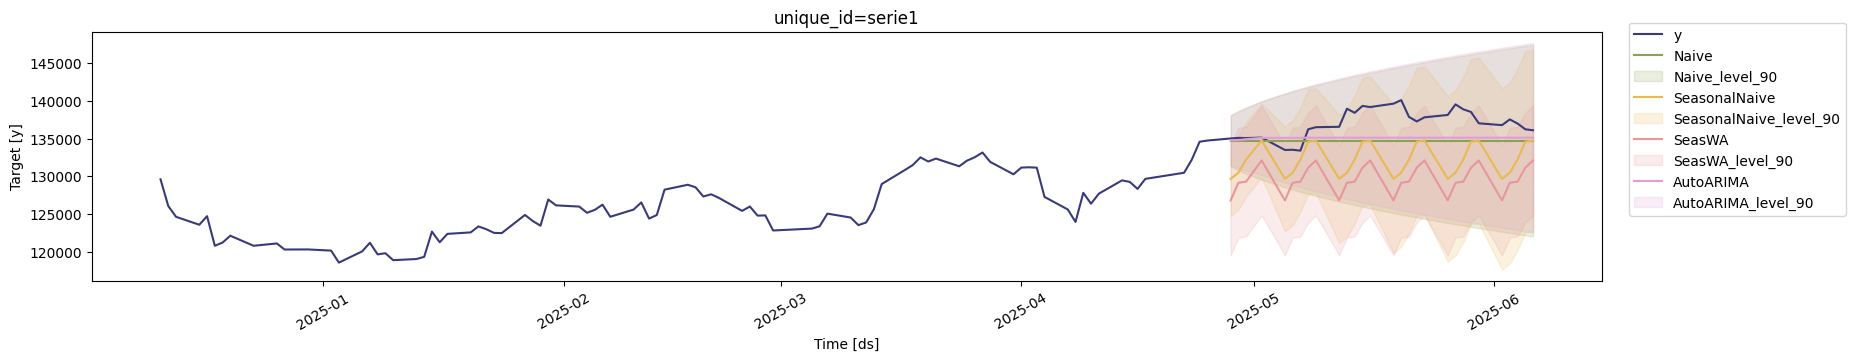

In [31]:
grafico_puro, forecast_df_puro, all_wmape_puro = modelos(df_puro, 'Fechamento', 7, 2)
grafico_puro

In [32]:
print("WMAPE Puro:")
print(f"Naive {all_wmape_puro[0]:.2%}")
print(f"SeasonalNaive: {all_wmape_puro[1]:.2%}")
print(f"SeasonalWindowAverage {all_wmape_puro[2]:.2%}")
print(f"AutoARIMA {all_wmape_puro[3]:.2%}")

WMAPE Puro:
Naive 1.88%
SeasonalNaive: 3.50%
SeasonalWindowAverage 5.41%
AutoARIMA 1.68%


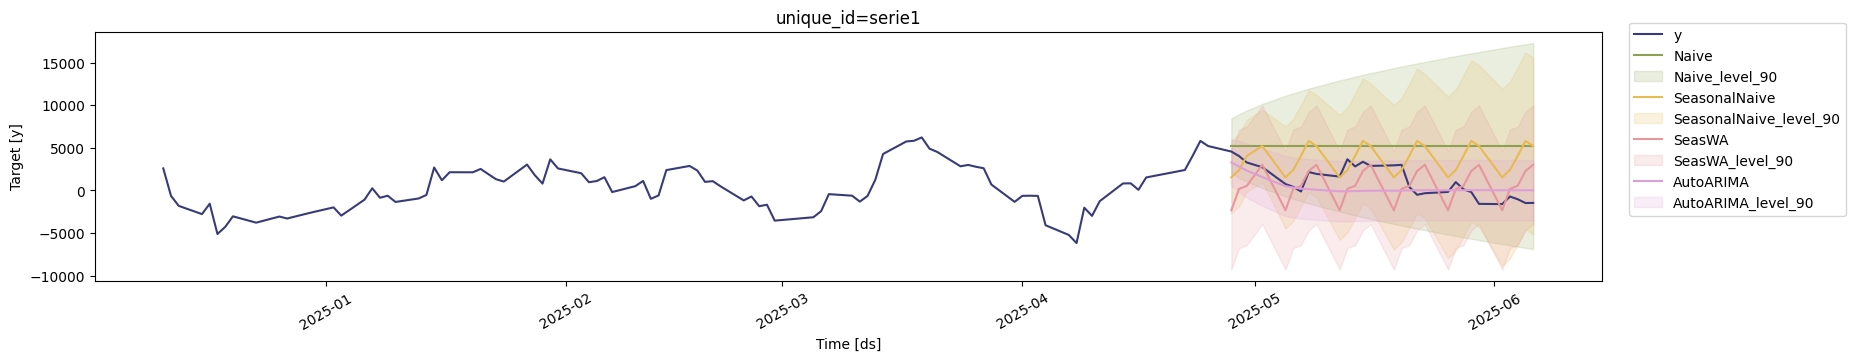

In [33]:
grafico_ma, forecast_df_ma, all_wmape_ma = modelos(df_ma, 'Fechamento', 7, 2)
grafico_ma

In [34]:
print("WMAPE Médias Móveis:")
print(f"Naive {all_wmape_ma[0]:.2%}")
print(f"SeasonalNaive: {all_wmape_ma[1]:.2%}")
print(f"SeasonalWindowAverage {all_wmape_ma[2]:.2%}")
print(f"AutoARIMA {all_wmape_ma[3]:.2%}")

WMAPE Médias Móveis:
Naive 233.44%
SeasonalNaive: 180.82%
SeasonalWindowAverage 129.97%
AutoARIMA 79.92%


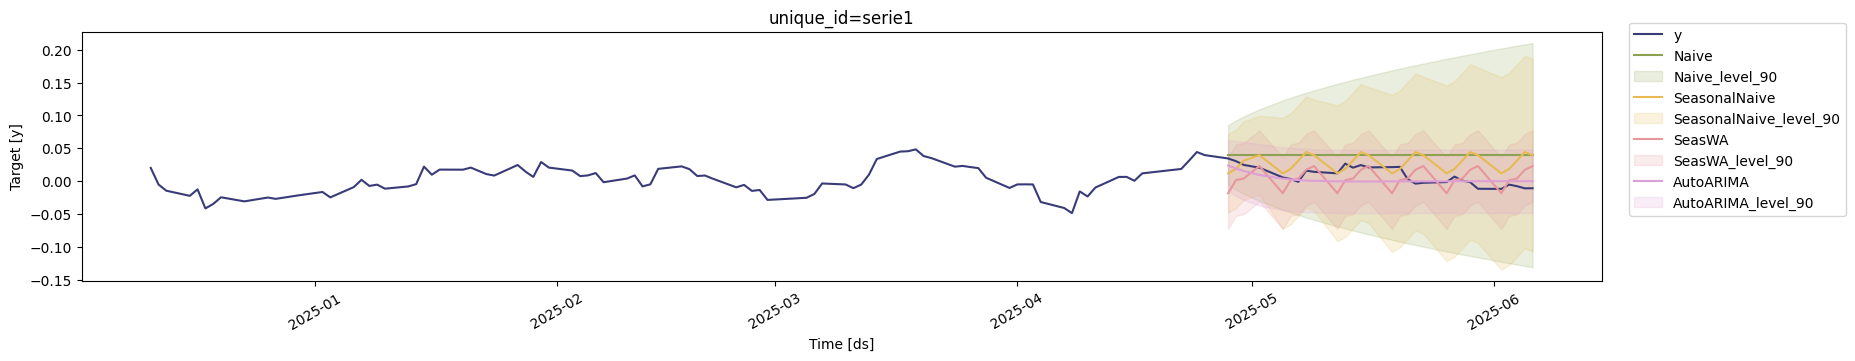

In [35]:
grafico_log, forecast_df_log, all_wmape_log = modelos(df_log, 'Fechamento', 7, 2)
grafico_log

In [36]:
print("WMAPE Logaritimo:")
print(f"Naive {all_wmape_log[0]:.2%}")
print(f"SeasonalNaive: {all_wmape_log[1]:.2%}")
print(f"SeasonalWindowAverage {all_wmape_log[2]:.2%}")
print(f"AutoARIMA {all_wmape_log[3]:.2%}")

WMAPE Logaritimo:
Naive 241.98%
SeasonalNaive: 186.36%
SeasonalWindowAverage 133.23%
AutoARIMA 80.69%


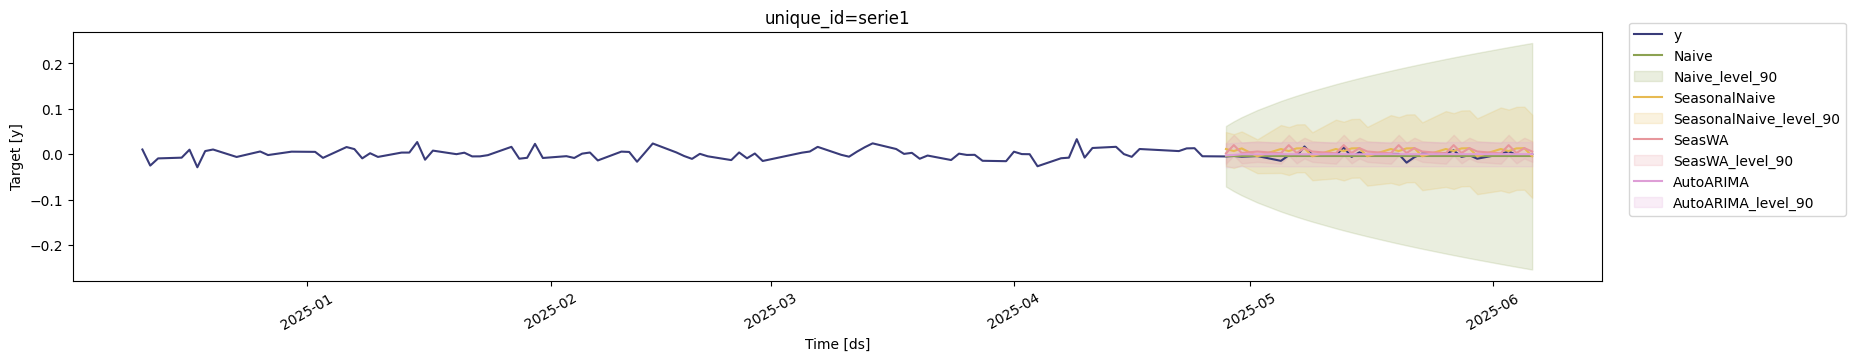

In [37]:
grafico_diff, forecast_df_diff, all_wmape_diff = modelos(df_diff, 'Fechamento', 7, 2)
grafico_diff

In [38]:
print("WMAPE Diferenciação:")
print(f"Naive {all_wmape_diff[0]:.2%}")
print(f"SeasonalNaive: {all_wmape_diff[1]:.2%}")
print(f"SeasonalWindowAverage {all_wmape_diff[2]:.2%}")
print(f"AutoARIMA {all_wmape_diff[3]:.2%}")

WMAPE Diferenciação:
Naive 99.68%
SeasonalNaive: 208.54%
SeasonalWindowAverage 192.00%
AutoARIMA 96.45%


**Nota sobre o WMAPE nas séries transformadas:** o erro (WMAPE) das versões "Médias Móveis", "Logaritmo" e "Diferenciação" aparece dezenas de vezes maior que o da série "Pura" — isso **não** significa necessariamente que o modelo piorou nessa proporção. O WMAPE divide o erro absoluto pela soma dos valores reais; nessas três versões os valores oscilam perto de zero (todas removem a tendência da série), o que faz o denominador ficar minúsculo e a métrica disparar de forma enganosa. Comparar o WMAPE dessas séries diretamente com o da série em nível (Puro) não é justo — a métrica não é comparável entre escalas tão diferentes. Isso reforça um ponto do próprio objetivo do projeto: métricas tradicionais nem sempre refletem o valor preditivo real de um modelo.


In [39]:
def classificar(row, modelo):
    if row['y'] == 'Aumentou' and row[modelo] == 'Aumentou':
        return 'TP'
    elif row['y'] == 'Aumentou' and row[modelo] == 'Diminuiu':
        return 'FN'
    elif row['y'] == 'Diminuiu' and row[modelo] == 'Aumentou':
        return 'FP'
    elif row['y'] == 'Diminuiu' and row[modelo] == 'Diminuiu':
        return 'TN'
    else:
        return 'Indefinido'

In [40]:
def calcular_acuracia(df, modelo):
    tp = df[df[f'{modelo}_Class'] == 'TP'].shape[0]
    tn = df[df[f'{modelo}_Class'] == 'TN'].shape[0]
    fp = df[df[f'{modelo}_Class'] == 'FP'].shape[0]
    fn = df[df[f'{modelo}_Class'] == 'FN'].shape[0]

    total = tp + tn + fp + fn
    if total == 0:
        return 0
    return (tp + tn) / total

In [41]:
def acuracia(df, forecast_df, y):
  data_inical = forecast_df['ds'].iloc[0]
  dia_antes = df.iloc[df.index.get_loc(data_inical) -1].name
  valor_antes = df.iloc[df.index.get_loc(data_inical) - 1][y]

  referencia = {'ds': pd.Timestamp(dia_antes), 'unique_id': 'serie1',  'y': valor_antes,
              'Naive': valor_antes, 'Naive-lo-90': valor_antes, 'Naive-hi-90': valor_antes,
              'SeasonalNaive': valor_antes, 'SeasonalNaive-lo-90': valor_antes, 'SeasonalNaive-hi-90': valor_antes,
              'SeasWA': valor_antes, 'SeasWA-lo-90': valor_antes, 'SeasWA-hi-90': valor_antes,
              'AutoARIMA': valor_antes, 'AutoARIMA-lo-90': valor_antes, 'AutoARIMA-hi-90': valor_antes}

  forecast_df = pd.concat([pd.DataFrame([referencia]), forecast_df], ignore_index=True)
  forecast_df.sort_values('ds', inplace=True)
  forecast_df.reset_index(drop=True, inplace=True)

  colunas = ['y', 'Naive', 'SeasonalNaive', 'SeasWA', 'AutoARIMA']
  diferencas = forecast_df[colunas].diff()
  resultado = pd.concat([forecast_df['ds'], diferencas], axis=1).dropna()

  comparacoes = resultado[['ds']].copy()

  for col in colunas:
    comparacoes[col + '_variação'] = resultado[col].apply(
        lambda x: 'Aumentou' if x > 0 else 'Diminuiu')

  comparacoes.columns = ['ds', 'y', 'Naive', 'SeasonalNaive', 'SeasWA', 'AutoARIMA']

  modelos = ['Naive', 'SeasonalNaive', 'SeasWA', 'AutoARIMA']

  for modelo in modelos:
    comparacoes[f'{modelo}_Class'] = comparacoes.apply(lambda row: classificar(row, modelo), axis=1)

  for modelo in modelos:
    print(f'='*40)
    print(f'{modelo}:')
    acuracia = calcular_acuracia(comparacoes, modelo)
    print(f'Acurácia do modelo {modelo}: {acuracia:.2f}')
    print(comparacoes[f'{modelo}_Class'].value_counts())

In [42]:
acuracia(df_puro, forecast_df_puro, 'Fechamento')

Naive:
Acurácia do modelo Naive: 0.48
Naive_Class
FN    15
TN    14
Name: count, dtype: int64
SeasonalNaive:
Acurácia do modelo SeasonalNaive: 0.45
SeasonalNaive_Class
FP    12
TP    11
FN     4
TN     2
Name: count, dtype: int64
SeasWA:
Acurácia do modelo SeasWA: 0.45
SeasWA_Class
FP    12
TP    11
FN     4
TN     2
Name: count, dtype: int64
AutoARIMA:
Acurácia do modelo AutoARIMA: 0.52
AutoARIMA_Class
TP    15
FP    14
Name: count, dtype: int64


In [43]:
acuracia(df_ma, forecast_df_ma, 'Fechamento')

Naive:
Acurácia do modelo Naive: 0.66
Naive_Class
TN    19
FN    10
Name: count, dtype: int64
SeasonalNaive:
Acurácia do modelo SeasonalNaive: 0.45
SeasonalNaive_Class
FP    12
TN     7
TP     6
FN     4
Name: count, dtype: int64
SeasWA:
Acurácia do modelo SeasWA: 0.41
SeasWA_Class
FP    15
TP     8
TN     4
FN     2
Name: count, dtype: int64
AutoARIMA:
Acurácia do modelo AutoARIMA: 0.62
AutoARIMA_Class
TN    12
FP     7
TP     6
FN     4
Name: count, dtype: int64


In [44]:
acuracia(df_log, forecast_df_log, 'Fechamento')

Naive:
Acurácia do modelo Naive: 0.66
Naive_Class
TN    19
FN    10
Name: count, dtype: int64
SeasonalNaive:
Acurácia do modelo SeasonalNaive: 0.45
SeasonalNaive_Class
FP    12
TN     7
TP     6
FN     4
Name: count, dtype: int64
SeasWA:
Acurácia do modelo SeasWA: 0.41
SeasWA_Class
FP    15
TP     8
TN     4
FN     2
Name: count, dtype: int64
AutoARIMA:
Acurácia do modelo AutoARIMA: 0.62
AutoARIMA_Class
TN    12
FP     7
TP     6
FN     4
Name: count, dtype: int64


In [45]:
acuracia(df_diff, forecast_df_diff, 'Fechamento')

Naive:
Acurácia do modelo Naive: 0.52
Naive_Class
TN    15
FN    14
Name: count, dtype: int64
SeasonalNaive:
Acurácia do modelo SeasonalNaive: 0.34
SeasonalNaive_Class
FP    11
FN     8
TP     6
TN     4
Name: count, dtype: int64
SeasWA:
Acurácia do modelo SeasWA: 0.76
SeasWA_Class
TN    12
TP    10
FN     4
FP     3
Name: count, dtype: int64
AutoARIMA:
Acurácia do modelo AutoARIMA: 0.24
AutoARIMA_Class
FP    13
FN     9
TP     5
TN     2
Name: count, dtype: int64


In [46]:
def profetas(df, y):
  df_1 = df.copy()
  df_1.reset_index(inplace=True)
  df_1 = df_1.rename(columns={'Data':'ds', y:'y'})

  treino = df_1[:-30]
  valid = df_1[-30:]
  h = valid['ds'].nunique()
  i = treino['ds'].nunique()
  treino['unique_id'] = 'serie1'
  valid['unique_id'] = 'serie1'

  np.random.seed(4587)

  modelo = Prophet()
  modelo.fit(treino)

  previsao = modelo.predict(valid)
  forecast_df_pro = previsao[['ds', 'yhat_lower', 'yhat_upper','yhat']]

  forecast_df_pro = forecast_df_pro.reset_index(drop=True).merge(valid, on=['ds'], how='left')

  wmape_pro = wmape(forecast_df_pro['y'].values, forecast_df_pro['yhat'].values)

  return modelo, forecast_df_pro, wmape_pro

In [47]:
modelo_puro_pro, forecast_df_puro_pro, wmape_puro_pro = profetas(df_puro, 'Fechamento')
modelo_ma_pro, forecast_df_ma_pro, wmape_ma_pro = profetas(df_ma, 'Fechamento')
modelo_log_pro, forecast_df_log_pro, wmape_log_pro = profetas(df_log, 'Fechamento')
modelo_diff_pro, forecast_df_diff_pro, wmape_diff_pro = profetas(df_diff, 'Fechamento')

02:04:46 - cmdstanpy - INFO - Chain [1] start processing


02:04:47 - cmdstanpy - INFO - Chain [1] done processing


02:04:47 - cmdstanpy - INFO - Chain [1] start processing


02:04:48 - cmdstanpy - INFO - Chain [1] done processing


02:04:48 - cmdstanpy - INFO - Chain [1] start processing


02:04:48 - cmdstanpy - INFO - Chain [1] done processing


02:04:48 - cmdstanpy - INFO - Chain [1] start processing


02:04:49 - cmdstanpy - INFO - Chain [1] done processing


(80000.0, 140000.0)

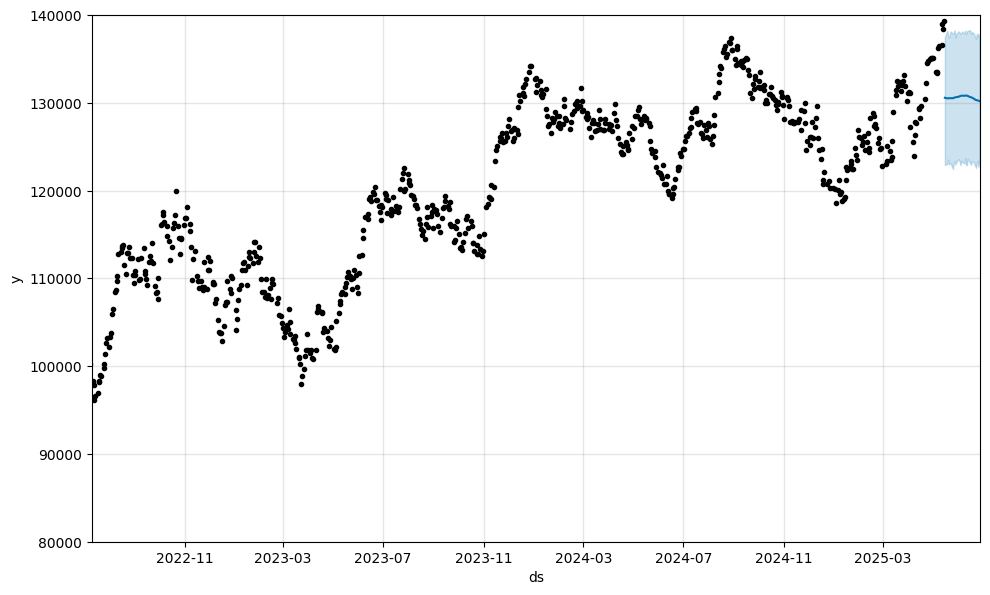

In [48]:
  fig = modelo_puro_pro.plot(forecast_df_puro_pro.dropna())
  ax  = fig.gca()

  data_inicio = pd.to_datetime(forecast_df_puro_pro['ds'].min()) - pd.Timedelta(days=1040)
  data_fim    = pd.to_datetime(forecast_df_puro_pro['ds'].max()) + pd.Timedelta(days=1)

  ax.set_xlim(data_inicio, data_fim)
  ax.set_ylim(80000, 140000)

(80000.0, 140000.0)

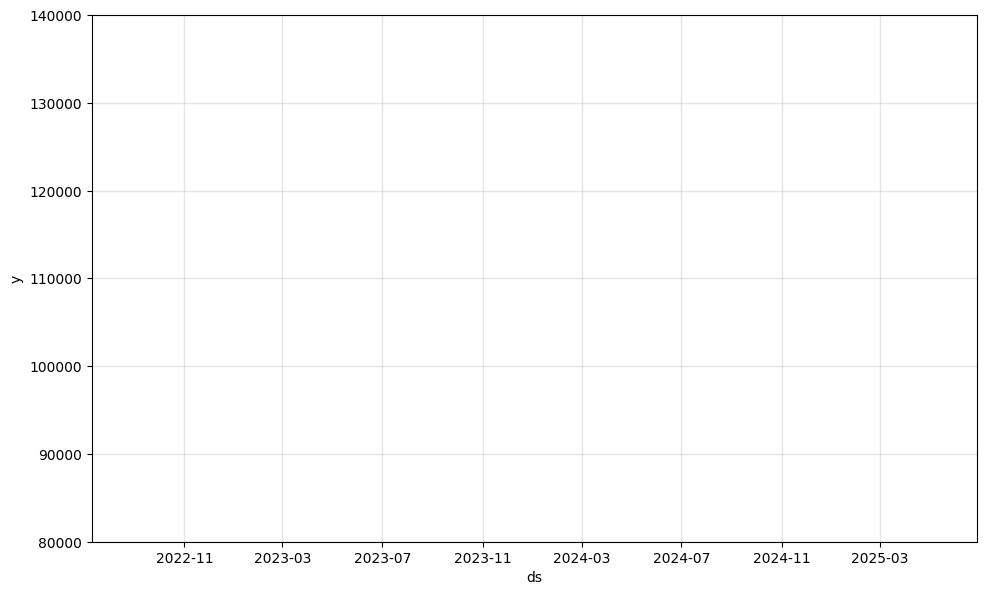

In [49]:
  fig = modelo_ma_pro.plot(forecast_df_ma_pro.dropna())
  ax  = fig.gca()

  data_inicio = pd.to_datetime(forecast_df_ma_pro['ds'].min()) - pd.Timedelta(days=1040)
  data_fim    = pd.to_datetime(forecast_df_ma_pro['ds'].max()) + pd.Timedelta(days=1)

  ax.set_xlim(data_inicio, data_fim)
  ax.set_ylim(80000, 140000)

(-0.1, 0.1)

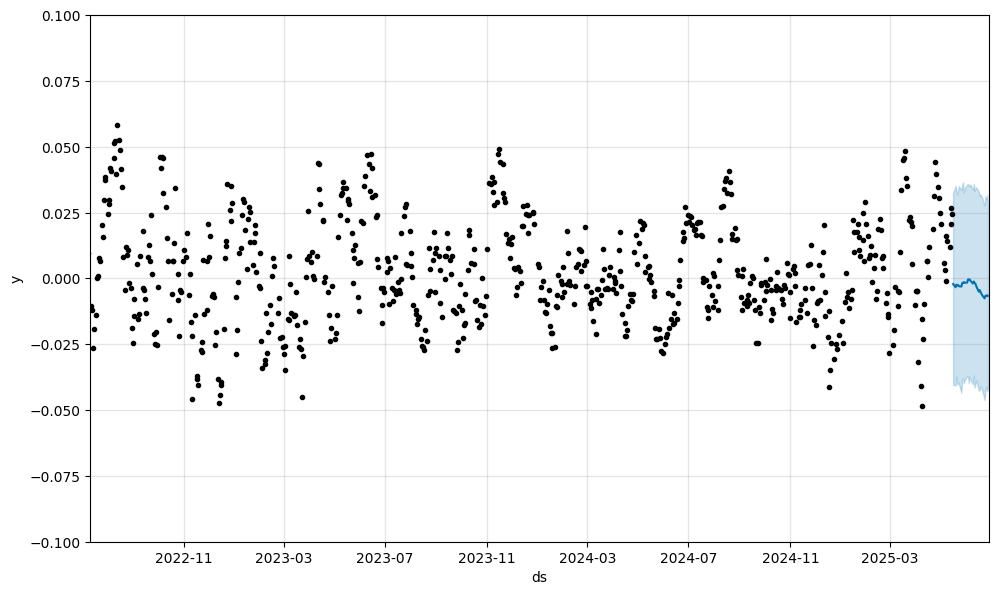

In [50]:
  fig = modelo_log_pro.plot(forecast_df_log_pro.dropna())
  ax  = fig.gca()

  data_inicio = pd.to_datetime(forecast_df_log_pro['ds'].min()) - pd.Timedelta(days=1040)
  data_fim    = pd.to_datetime(forecast_df_log_pro['ds'].max()) + pd.Timedelta(days=1)

  ax.set_xlim(data_inicio, data_fim)
  ax.set_ylim(-0.10, 0.10)

(-0.1, 0.1)

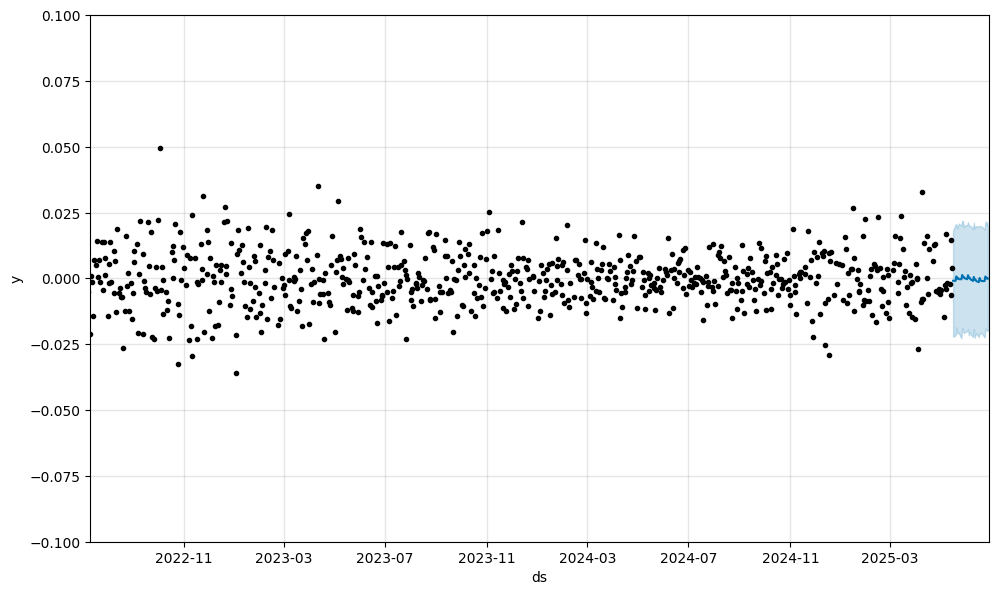

In [51]:
  fig = modelo_diff_pro.plot(forecast_df_diff_pro.dropna())
  ax  = fig.gca()

  data_inicio = pd.to_datetime(forecast_df_diff_pro['ds'].min()) - pd.Timedelta(days=1040)
  data_fim    = pd.to_datetime(forecast_df_diff_pro['ds'].max()) + pd.Timedelta(days=1)

  ax.set_xlim(data_inicio, data_fim)
  ax.set_ylim(-0.10, 0.10)

In [52]:
print("WMAPE Prophet:")
print(f"Puro {wmape_puro_pro:.2%}")
print(f"Médias Móveis: {wmape_ma_pro:.2%}")
print(f"Logaritimo {wmape_log_pro:.2%}")
print(f"Diferenciado {wmape_diff_pro:.2%}")

WMAPE Prophet:
Puro 5.13%
Médias Móveis: 102.25%
Logaritimo 108.02%
Diferenciado 97.38%


O mesmo efeito aparece aqui: o Prophet também erra muito mais (em termos de WMAPE) nas versões Médias Móveis, Logaritmo e Diferenciado do que na série Pura — pelo mesmo motivo já discutido (WMAPE não é uma métrica confiável quando os valores oscilam perto de zero). Isso não invalida o Prophet nessas representações; só significa que o WMAPE não é a métrica certa para compará-las nesse caso.


In [53]:
forecast_df_diff_pro

,ds,yhat_lower,yhat_upper,yhat,y,unique_id
0,2025-05-16,-0.022178,0.018230,-0.000916,-0.003543,serie1
1,2025-05-19,-0.021671,0.020461,-0.000945,0.000448,serie1
2,2025-05-20,-0.018644,0.020571,0.000745,0.000375,serie1
3,2025-05-21,-0.020986,0.019050,-0.000089,-0.018733,serie1
4,2025-05-22,-0.020383,0.019986,0.000103,-0.006732,serie1
5,2025-05-23,-0.020932,0.020804,-0.000298,0.001286,serie1
6,2025-05-26,-0.022776,0.020036,-0.000349,0.001105,serie1
7,2025-05-27,-0.018958,0.021924,0.001298,0.008291,serie1
8,2025-05-28,-0.019720,0.021640,0.000406,-0.006097,serie1
9,2025-05-29,-0.020787,0.019438,0.000523,-0.002294,serie1


In [54]:
def acuracia_pro(df, forecast_df, y):
  data_inical = forecast_df['ds'].iloc[0]
  dia_antes = df.iloc[df.index.get_loc(data_inical) -1].name
  valor_antes = df.iloc[df.index.get_loc(data_inical) - 1][y]

  referencia = {'ds': pd.Timestamp(dia_antes), 'unique_id': 'serie1',  'y': valor_antes, 'yhat': valor_antes,
                'yhat_lower': valor_antes, 'yhat_upper': valor_antes}

  forecast_df = pd.concat([pd.DataFrame([referencia]), forecast_df], ignore_index=True)
  forecast_df.sort_values('ds', inplace=True)
  forecast_df.reset_index(drop=True, inplace=True)

  colunas = ['y', 'yhat']
  diferencas = forecast_df[colunas].diff()
  resultado = pd.concat([forecast_df['ds'], diferencas], axis=1).dropna()

  comparacoes = resultado[['ds']].copy()

  for col in colunas:
    comparacoes[col + '_variação'] = resultado[col].apply(
        lambda x: 'Aumentou' if x > 0 else 'Diminuiu')

  comparacoes.columns = ['ds', 'y', 'Prophet']

  modelos = ['Prophet']

  for modelo in modelos:
    comparacoes[f'{modelo}_Class'] = comparacoes.apply(lambda row: classificar(row, modelo), axis=1)

  for modelo in modelos:
    print(f'='*40)
    print(f'{modelo}:')
    acuracia = calcular_acuracia(comparacoes, modelo)
    print(f'Acurácia do modelo {modelo}: {acuracia:.2f}')
    print(comparacoes[f'{modelo}_Class'].value_counts())

In [55]:
datasets = [df_puro, df_ma, df_log, df_diff]
forecast_dfs = [forecast_df_puro_pro, forecast_df_ma_pro, forecast_df_log_pro, forecast_df_diff_pro]
nomes_datasets = ['Puro', 'Médias Móveis', 'Logaritimo', 'Diferenciado']

for dataset, forecast_df, nome  in zip(datasets, forecast_dfs, nomes_datasets):
  print(f'='*40)
  print(f'Dataset: {nome}')
  acuracia_pro(dataset, forecast_df, 'Fechamento')

Dataset: Puro
Prophet:
Acurácia do modelo Prophet: 0.50
Prophet_Class
TN    10
FP     8
FN     7
TP     5
Name: count, dtype: int64
Dataset: Médias Móveis
Prophet:
Acurácia do modelo Prophet: 0.70
Prophet_Class
TN    15
FN     7
TP     6
FP     2
Name: count, dtype: int64
Dataset: Logaritimo
Prophet:
Acurácia do modelo Prophet: 0.57
Prophet_Class
TN    11
FN     7
TP     6
FP     6
Name: count, dtype: int64
Dataset: Diferenciado
Prophet:
Acurácia do modelo Prophet: 0.70
Prophet_Class
TN    12
TP     9
FN     6
FP     3
Name: count, dtype: int64


## Conclusão

Entre os modelos testados, o **AutoARIMA** e o **Prophet** aplicados diretamente sobre a série em nível ("Puro") tiveram o menor erro de previsão de curto prazo. Já a acurácia direcional (acertar se o índice vai subir ou descer no dia seguinte) ficou, na maioria dos casos, próxima de 50% — ou seja, próxima do que se esperaria de um "chute" aleatório, o que é consistente com a natureza ruidosa e de curto prazo difícil de prever do mercado financeiro.

A maior lição do projeto não foi encontrar um modelo vencedor, e sim entender **onde os números podem enganar**: métricas de erro relativo como o WMAPE precisam ser interpretadas com cuidado em séries transformadas (log, diferenciação), e alta acurácia de curto prazo em preços de ações não implica necessariamente capacidade preditiva real.
